# MicroDuck · 官方步态演示
这份 Notebook 使用和 Qwen 演示相同的 2×2 MuJoCo 场景与 Pollen Robotics 的官方步态，
直接执行你选择的动作。画面展示机器人第一视角、俯视位置和轨迹。无需下载 Qwen 权重，也不需要 GPU。

按顺序运行前两格。第三格选择前进、左转、右转或停止，再点击运行。每次都从同一个场景起点重置。
与 Qwen 版对比时，可先用这一页展示同一台仿真机器人如何执行手动动作，再切换到中文找球任务。

In [9]:
# @title 1 · 安装原始 MicroDuck 仿真环境
project_source = "drive"  # @param ["github", "drive", "upload"]
drive_folder = "microduck-qwen"  # @param {type:"string"}
render_backend = "osmesa"  # @param ["egl", "osmesa"]

import os
import shutil
import subprocess
import sys
import tempfile
import tomllib
import zipfile
from pathlib import Path

if sys.version_info[:2] not in ((3, 12), (3, 13)):
    raise RuntimeError("请选择 Python 3.12 或 3.13 的运行时，然后重新运行。")
root = Path("/content/microduck-qwen-github" if project_source == "github" else "/content/microduck-qwen")
bundle = "microduck-qwen-colab-source.zip"
local_zip = Path("/content") / bundle
if project_source == "github":
    if not (root / "pyproject.toml").is_file():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/atlasmarkz/microduck-qwen.git", str(root)], check=True)
else:
    if local_zip.is_file():
        print("使用已有的源码包。")
    elif project_source == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        source = Path("/content/drive/MyDrive") / drive_folder / bundle
        if not source.is_file():
            raise FileNotFoundError(f"未找到 {source}，也可切换到 github 或 upload。")
        shutil.copyfile(source, local_zip)
    else:
        from google.colab import files
        uploaded = files.upload()
        if bundle not in uploaded:
            raise FileNotFoundError(f"请选择 {bundle}。")
        local_zip.write_bytes(uploaded[bundle])
    with zipfile.ZipFile(local_zip) as archive:
        archive.extractall(root)

os.environ["MUJOCO_GL"] = render_backend
os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
os.chdir(root)
sys.path.insert(0, str(root))

def run(*cmd):
    completed = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if completed.returncode:
        raise RuntimeError(completed.stdout[-8500:])
    if completed.stdout.strip():
        print(completed.stdout[-2500:], flush=True)

gl_packages = ("libegl1", "libgl1") if render_backend == "egl" else ("libosmesa6", "libgl1")
subprocess.run(["apt-get", "-qq", "update"], check=True)
run("apt-get", "-qq", "-y", "install", *gl_packages)
project = tomllib.loads((root / "pyproject.toml").read_text())["project"]
requirements = project["optional-dependencies"]
bam = Path("/content/microduck-bam.zip")
bam_url = next(item.split(" @ ", 1)[1] for item in requirements["simulation"] if " @ " in item)
run("curl", "-fsSL", "--retry", "3", bam_url, "-o", str(bam))
sim_packages = [item for item in requirements["simulation"] if " @ " not in item]
with tempfile.TemporaryDirectory() as build:
    bam_source = bam
    if sys.version_info[:2] == (3, 13):
        # This demo uses only BAM's NumPy and MuJoCo path. Keep its pinned code
        # and model parameters, and widen just the source build's Python metadata.
        with zipfile.ZipFile(bam) as archive:
            archive.extractall(build)
        manifest, = Path(build).glob("bam-*/pyproject.toml")
        config = manifest.read_text(encoding="utf-8")
        guard = 'requires-python = ">=3.12,<3.13"'
        if config.count(guard) != 1:
            raise RuntimeError("固定版 BAM 的 Python 声明与预期不符。")
        manifest.write_text(config.replace(guard, 'requires-python = ">=3.12,<3.14"'),
                            encoding="utf-8")
        bam_source = manifest.parent
    run(sys.executable, "-m", "pip", "install", "-q", "huggingface-hub", "Pillow>=10.1",
        *sim_packages, str(bam_source))
print("依赖安装完成。")

Mounted at /content/drive
依赖安装完成。


In [10]:
# @title 2 · 下载官方 ONNX 步态和仿真资产
import tarfile
import tempfile
from huggingface_hub import hf_hub_download
from microduck_qwen.sim_native import DEFAULT_POLICY, DEFAULT_RL, POLICY_REVISION
hf_hub_download("pollen-robotics/microduck-policies", "alpha_walking.onnx",
                revision=POLICY_REVISION, cache_dir=DEFAULT_POLICY.parents[3], token=False)

upstream_rev = "0daab160d3fb1c2cbaba16a4a19052f36709dd9e"
if not DEFAULT_RL.exists():
    DEFAULT_RL.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(dir=DEFAULT_RL.parent) as temporary:
        upstream_archive = Path(temporary) / "upstream.tar.gz"
        run("curl", "-fsSL", "--retry", "3",
            f"https://codeload.github.com/pollen-robotics/microduck_rl/tar.gz/{upstream_rev}",
            "-o", str(upstream_archive))
        with tarfile.open(upstream_archive) as archive:
            archive.extractall(temporary, filter="data")
        (Path(temporary) / f"microduck_rl-{upstream_rev}").rename(DEFAULT_RL)

assert DEFAULT_POLICY.is_file(), "官方步态下载不完整。"
print("官方步态和仿真资产就绪。")

官方步态和仿真资产就绪。



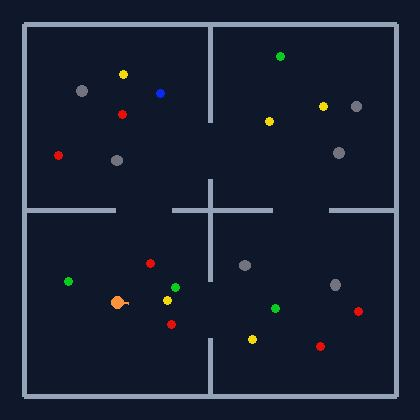
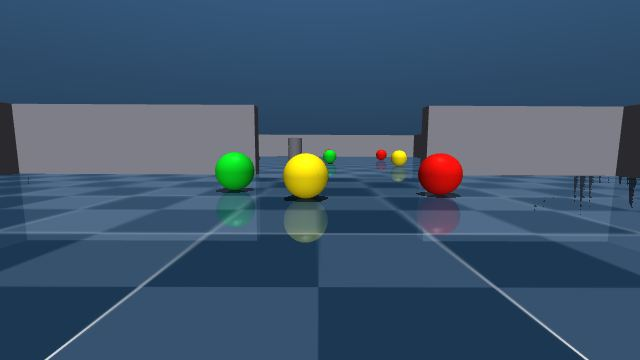

RuntimeError: camera stale (1.74s)

In [11]:
# @title 3 · 选择手动动作
motion = "forward"  # @param ["forward", "left", "right", "stop"]
seed = 98107  # @param {type:"integer"}

from microduck_qwen.colab_demo import live_baseline
result = live_baseline(motion, seed)
print("结果：", result)